In [1]:
# Cell 1: Environment Setup

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import random
import os
import time

# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
Selected device: cuda
GPU name: Tesla T4


In [2]:
# Cell 2: Download and Extract the Facades Dataset

import os
import tarfile
import urllib.request

DATASET_URL = "https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz"
DATA_ROOT = "/content/pix2pix_data"
ARCHIVE_PATH = "/content/facades.tar.gz"

os.makedirs(DATA_ROOT, exist_ok=True)

if not os.path.exists(os.path.join(DATA_ROOT, "facades")):
    print("Downloading Facades dataset...")

    urllib.request.urlretrieve(DATASET_URL, ARCHIVE_PATH)

    print("Extracting dataset...")

    with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
        tar.extractall(DATA_ROOT, filter="data")

    print("Dataset downloaded and extracted successfully!")
else:
    print("Dataset already exists. Skipping download.")

print("\nDataset directory:", DATA_ROOT)
print("Available folders:", os.listdir(os.path.join(DATA_ROOT, "facades")))

Extracting dataset...
Dataset downloaded and extracted successfully!

Dataset directory: /content/pix2pix_data
Available folders: ['val', 'train', 'test']


Number of training images: 400
Number of validation images: 100
Number of test images: 106


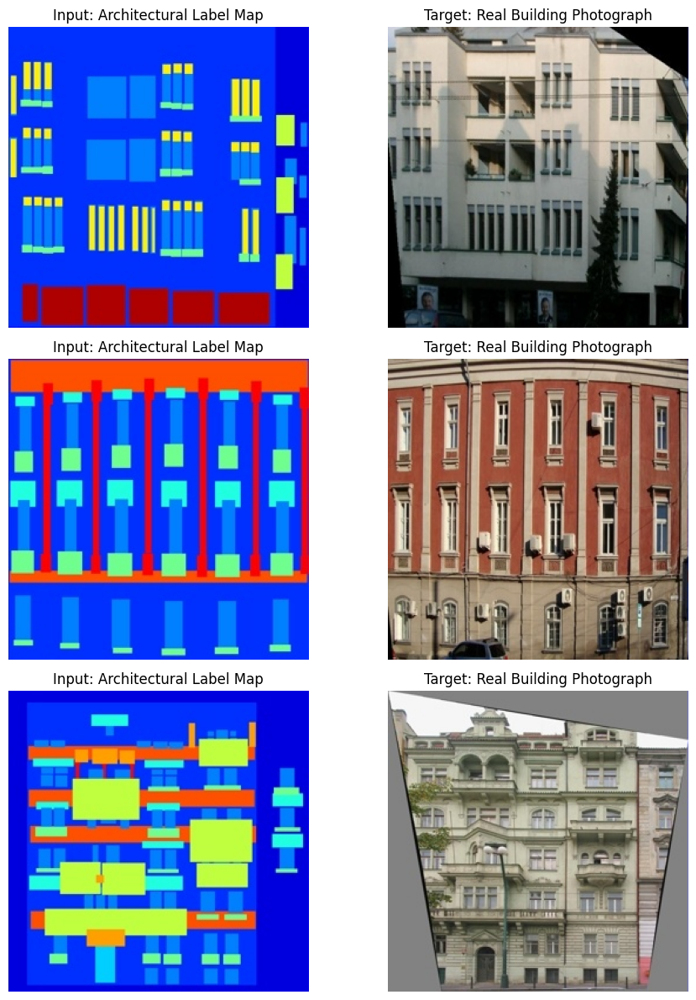

In [5]:
# Cell 3: Visualize the Facades Dataset Correctly

import os
import glob
from PIL import Image
import matplotlib.pyplot as plt

# Dataset directories
TRAIN_DIR = "/content/pix2pix_data/facades/train"
VAL_DIR = "/content/pix2pix_data/facades/val"
TEST_DIR = "/content/pix2pix_data/facades/test"

# Collect image paths
train_images = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.jpg")))
val_images = sorted(glob.glob(os.path.join(VAL_DIR, "*.jpg")))
test_images = sorted(glob.glob(os.path.join(TEST_DIR, "*.jpg")))

print("Number of training images:", len(train_images))
print("Number of validation images:", len(val_images))
print("Number of test images:", len(test_images))


def split_facades_image(image_path):
    """
    Facades dataset:
    Left half  = real building photograph
    Right half = architectural label map

    Our Pix2Pix task:
    Input  = architectural label map
    Target = real building photograph
    """
    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    real_photo = image.crop((0, 0, width // 2, height))
    label_map = image.crop((width // 2, 0, width, height))

    return label_map, real_photo


# Display three examples
num_examples = min(3, len(train_images))

fig, axes = plt.subplots(num_examples, 2, figsize=(10, 4 * num_examples))

if num_examples == 1:
    axes = axes.reshape(1, 2)

for i in range(num_examples):
    input_image, target_image = split_facades_image(train_images[i])

    axes[i, 0].imshow(input_image)
    axes[i, 0].set_title("Input: Architectural Label Map")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(target_image)
    axes[i, 1].set_title("Target: Real Building Photograph")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

Full image size: (512, 256)


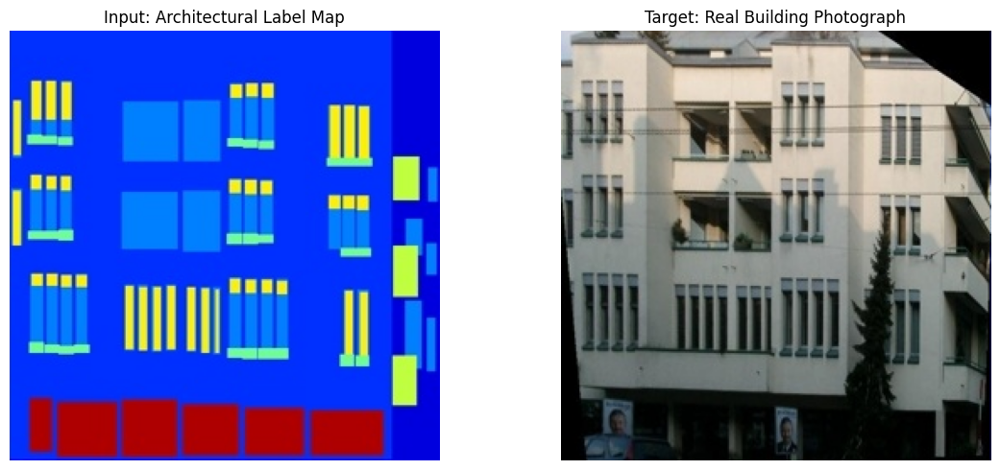

In [6]:
# Cell 4: Correct Input and Target Image Ordering

from PIL import Image
import matplotlib.pyplot as plt
import glob
import os

TRAIN_DIR = "/content/pix2pix_data/facades/train"
train_images = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.jpg")))

sample_path = train_images[0]
paired_image = Image.open(sample_path).convert("RGB")

width, height = paired_image.size
print("Full image size:", paired_image.size)

# Correct ordering for the Facades translation task:
# Left half  = real photograph
# Right half = architectural label map

real_photo = paired_image.crop((0, 0, width // 2, height))
label_map = paired_image.crop((width // 2, 0, width, height))

# Set the intended Pix2Pix direction
input_image = label_map
target_image = real_photo

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(input_image)
axes[0].set_title("Input: Architectural Label Map")
axes[0].axis("off")

axes[1].imshow(target_image)
axes[1].set_title("Target: Real Building Photograph")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Cell 5: Create the Facades Dataset Loader

import os
import glob
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Dataset paths
DATA_ROOT = "/content/pix2pix_data/facades"

TRAIN_DIR = os.path.join(DATA_ROOT, "train")
VAL_DIR = os.path.join(DATA_ROOT, "val")
TEST_DIR = os.path.join(DATA_ROOT, "test")

# Image settings
IMAGE_SIZE = 256
BATCH_SIZE = 1

# Convert images to tensors and normalize RGB values from [0, 1] to [-1, 1]
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])


class FacadesDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_paths = sorted(
            glob.glob(os.path.join(image_dir, "*.jpg"))
        )
        self.transform = transform

        if len(self.image_paths) == 0:
            raise RuntimeError(f"No .jpg images found in {image_dir}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        # Load the paired image
        paired_image = Image.open(self.image_paths[index]).convert("RGB")

        width, height = paired_image.size

        # Facades dataset ordering:
        # Left half  = real photograph
        # Right half = architectural label map
        real_photo = paired_image.crop((0, 0, width // 2, height))
        label_map = paired_image.crop((width // 2, 0, width, height))

        # Our task: label map -> real photograph
        input_image = label_map
        target_image = real_photo

        if self.transform is not None:
            input_image = self.transform(input_image)
            target_image = self.transform(target_image)

        return input_image, target_image


# Create datasets
train_dataset = FacadesDataset(TRAIN_DIR, transform=transform)
val_dataset = FacadesDataset(VAL_DIR, transform=transform)
test_dataset = FacadesDataset(TEST_DIR, transform=transform)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Dataset loader created successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)

Dataset loader created successfully!
Training samples: 400
Validation samples: 100
Testing samples: 106
Batch size: 1
Image size: 256


Input batch shape: torch.Size([1, 3, 256, 256])
Target batch shape: torch.Size([1, 3, 256, 256])
Input value range: -1.0 1.0
Target value range: -1.0 0.8823529481887817


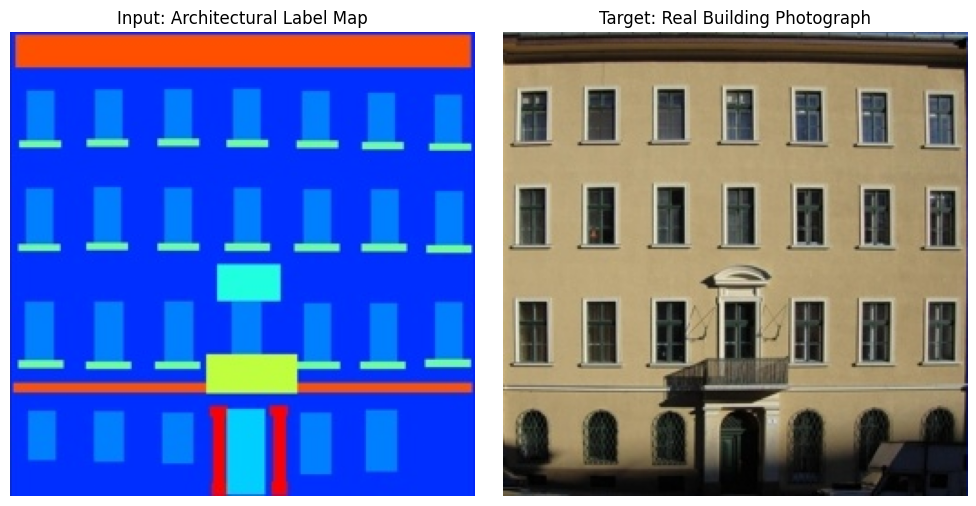

In [8]:
# Cell 5.1: Verify One Training Batch

input_batch, target_batch = next(iter(train_loader))

print("Input batch shape:", input_batch.shape)
print("Target batch shape:", target_batch.shape)
print("Input value range:", input_batch.min().item(), input_batch.max().item())
print("Target value range:", target_batch.min().item(), target_batch.max().item())

# Convert normalized tensors back to displayable images
input_display = (input_batch[0].permute(1, 2, 0).cpu() * 0.5 + 0.5).clamp(0, 1)
target_display = (target_batch[0].permute(1, 2, 0).cpu() * 0.5 + 0.5).clamp(0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(input_display)
axes[0].set_title("Input: Architectural Label Map")
axes[0].axis("off")

axes[1].imshow(target_display)
axes[1].set_title("Target: Real Building Photograph")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
# Cell 6: Pix2Pix U-Net Generator

import torch
import torch.nn as nn


def down_block(in_channels, out_channels, use_batchnorm=True):
    layers = [
        nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1,
            bias=not use_batchnorm
        )
    ]

    if use_batchnorm:
        layers.append(nn.BatchNorm2d(out_channels))

    layers.append(nn.LeakyReLU(0.2, inplace=True))

    return nn.Sequential(*layers)


def up_block(in_channels, out_channels, dropout=False):
    layers = [
        nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1,
            bias=False
        ),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    ]

    if dropout:
        layers.append(nn.Dropout(0.5))

    return nn.Sequential(*layers)


class UNetGenerator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, base_channels=32):
        super().__init__()

        # Encoder: 256 -> 128 -> 64 -> 32 -> 16 -> 8 -> 4 -> 2 -> 1
        self.down1 = down_block(in_channels, base_channels, False)
        self.down2 = down_block(base_channels, base_channels * 2)
        self.down3 = down_block(base_channels * 2, base_channels * 4)
        self.down4 = down_block(base_channels * 4, base_channels * 8)
        self.down5 = down_block(base_channels * 8, base_channels * 8)
        self.down6 = down_block(base_channels * 8, base_channels * 8)
        self.down7 = down_block(base_channels * 8, base_channels * 8)
        self.down8 = down_block(base_channels * 8, base_channels * 8, False)

        # Decoder with skip connections
        self.up1 = up_block(base_channels * 8, base_channels * 8, True)
        self.up2 = up_block(base_channels * 16, base_channels * 8, True)
        self.up3 = up_block(base_channels * 16, base_channels * 8, True)
        self.up4 = up_block(base_channels * 16, base_channels * 8)
        self.up5 = up_block(base_channels * 16, base_channels * 4)
        self.up6 = up_block(base_channels * 8, base_channels * 2)
        self.up7 = up_block(base_channels * 4, base_channels)

        self.final_layer = nn.Sequential(
            nn.ConvTranspose2d(
                base_channels * 2,
                out_channels,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.Tanh()
        )

    def forward(self, x):
        # Encoder
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        # Decoder + skip connections
        u1 = self.up1(d8)
        u2 = self.up2(torch.cat([u1, d7], dim=1))
        u3 = self.up3(torch.cat([u2, d6], dim=1))
        u4 = self.up4(torch.cat([u3, d5], dim=1))
        u5 = self.up5(torch.cat([u4, d4], dim=1))
        u6 = self.up6(torch.cat([u5, d3], dim=1))
        u7 = self.up7(torch.cat([u6, d2], dim=1))

        output = self.final_layer(torch.cat([u7, d1], dim=1))

        return output


# Initialize generator
generator = UNetGenerator(
    in_channels=3,
    out_channels=3,
    base_channels=32
).to(DEVICE)

print("Generator initialized successfully!")
print("Device:", next(generator.parameters()).device)
print("Trainable parameters:", sum(
    p.numel() for p in generator.parameters() if p.requires_grad
))

Generator initialized successfully!
Device: cuda:0
Trainable parameters: 13608547


In [10]:
# Cell 7: Conditional PatchGAN Discriminator

import torch
import torch.nn as nn


def discriminator_block(in_channels, out_channels, stride=2, use_batchnorm=True):
    layers = [
        nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=stride,
            padding=1,
            bias=not use_batchnorm
        )
    ]

    if use_batchnorm:
        layers.append(nn.BatchNorm2d(out_channels))

    layers.append(nn.LeakyReLU(0.2, inplace=True))

    return nn.Sequential(*layers)


class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_channels=6, base_channels=32):
        super().__init__()

        self.model = nn.Sequential(
            # 256 x 256 -> 128 x 128
            discriminator_block(in_channels, base_channels, use_batchnorm=False),

            # 128 x 128 -> 64 x 64
            discriminator_block(base_channels, base_channels * 2),

            # 64 x 64 -> 32 x 32
            discriminator_block(base_channels * 2, base_channels * 4),

            # 32 x 32 -> 31 x 31
            discriminator_block(
                base_channels * 4,
                base_channels * 8,
                stride=1
            ),

            # 31 x 31 -> 30 x 30
            nn.Conv2d(
                base_channels * 8,
                1,
                kernel_size=4,
                stride=1,
                padding=1
            )
        )

    def forward(self, input_image, target_image):
        # Concatenate input and target along the channel dimension
        combined = torch.cat([input_image, target_image], dim=1)

        # Return raw logits; sigmoid is handled by the loss function
        return self.model(combined)


# Initialize discriminator
discriminator = PatchGANDiscriminator(
    in_channels=6,
    base_channels=32
).to(DEVICE)

print("Discriminator initialized successfully!")
print("Device:", next(discriminator.parameters()).device)

print(
    "Trainable parameters:",
    sum(p.numel() for p in discriminator.parameters() if p.requires_grad)
)

Discriminator initialized successfully!
Device: cuda:0
Trainable parameters: 696225


In [11]:
# Cell 7.1: Verify Discriminator Output

generator.eval()
discriminator.eval()

with torch.no_grad():
    sample_input, sample_target = next(iter(train_loader))

    sample_input = sample_input.to(DEVICE)
    sample_target = sample_target.to(DEVICE)

    generated_image = generator(sample_input)

    real_prediction = discriminator(sample_input, sample_target)
    fake_prediction = discriminator(sample_input, generated_image)

print("Input image shape:", sample_input.shape)
print("Generated image shape:", generated_image.shape)
print("Real prediction shape:", real_prediction.shape)
print("Fake prediction shape:", fake_prediction.shape)

assert real_prediction.shape == fake_prediction.shape
assert real_prediction.shape[1] == 1

print("Discriminator forward pass successful!")

Input image shape: torch.Size([1, 3, 256, 256])
Generated image shape: torch.Size([1, 3, 256, 256])
Real prediction shape: torch.Size([1, 1, 30, 30])
Fake prediction shape: torch.Size([1, 1, 30, 30])
Discriminator forward pass successful!


In [12]:
# Cell 8: Loss Functions and Optimizers

import torch
import torch.nn as nn
import torch.optim as optim

# Adversarial loss
criterion_GAN = nn.BCEWithLogitsLoss()

# Pixel-wise reconstruction loss
criterion_L1 = nn.L1Loss()

# Weight of L1 reconstruction loss
LAMBDA_L1 = 100

# Adam optimizers
LEARNING_RATE = 0.0002
BETA1 = 0.5
BETA2 = 0.999

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2)
)

print("Loss functions initialized:")
print("  Adversarial loss: BCEWithLogitsLoss")
print("  Reconstruction loss: L1Loss")
print("  L1 weight:", LAMBDA_L1)

print("\nOptimizers initialized:")
print("  Optimizer: Adam")
print("  Learning rate:", LEARNING_RATE)
print("  Betas:", (BETA1, BETA2))

Loss functions initialized:
  Adversarial loss: BCEWithLogitsLoss
  Reconstruction loss: L1Loss
  L1 weight: 100

Optimizers initialized:
  Optimizer: Adam
  Learning rate: 0.0002
  Betas: (0.5, 0.999)


In [13]:
# Cell 8.1: Test Loss Functions

generator.train()
discriminator.train()

# Get one batch
real_input, real_target = next(iter(train_loader))

real_input = real_input.to(DEVICE)
real_target = real_target.to(DEVICE)

# Generate a fake photograph
fake_target = generator(real_input)

# Discriminator predictions
pred_real = discriminator(real_input, real_target)
pred_fake = discriminator(real_input, fake_target.detach())

# Real images should have label 1
loss_D_real = criterion_GAN(
    pred_real,
    torch.ones_like(pred_real)
)

# Generated images should have label 0
loss_D_fake = criterion_GAN(
    pred_fake,
    torch.zeros_like(pred_fake)
)

# Average discriminator loss
loss_D = 0.5 * (loss_D_real + loss_D_fake)

# Generator adversarial loss
pred_fake_for_G = discriminator(real_input, fake_target)

loss_G_GAN = criterion_GAN(
    pred_fake_for_G,
    torch.ones_like(pred_fake_for_G)
)

# Generator reconstruction loss
loss_G_L1 = criterion_L1(fake_target, real_target)

# Total generator loss
loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1

print(f"Discriminator real loss: {loss_D_real.item():.4f}")
print(f"Discriminator fake loss: {loss_D_fake.item():.4f}")
print(f"Total discriminator loss: {loss_D.item():.4f}")

print(f"\nGenerator adversarial loss: {loss_G_GAN.item():.4f}")
print(f"Generator L1 loss: {loss_G_L1.item():.4f}")
print(f"Total generator loss: {loss_G.item():.4f}")

assert torch.isfinite(loss_D), "Discriminator loss is not finite!"
assert torch.isfinite(loss_G), "Generator loss is not finite!"

print("\nLoss verification successful!")

Discriminator real loss: 0.7903
Discriminator fake loss: 0.6405
Total discriminator loss: 0.7154

Generator adversarial loss: 0.7836
Generator L1 loss: 0.6046
Total generator loss: 61.2391

Loss verification successful!


In [14]:
# Cell 9: Pix2Pix Training Loop

import time
import torch
import matplotlib.pyplot as plt

NUM_EPOCHS = 50

# Store loss history for plotting later
history = {
    "G_total": [],
    "G_GAN": [],
    "G_L1": [],
    "D_total": []
}

for epoch in range(NUM_EPOCHS):

    generator.train()
    discriminator.train()

    epoch_G_total = 0.0
    epoch_G_GAN = 0.0
    epoch_G_L1 = 0.0
    epoch_D_total = 0.0

    start_time = time.time()

    for batch_idx, (real_input, real_target) in enumerate(train_loader):

        real_input = real_input.to(DEVICE)
        real_target = real_target.to(DEVICE)

        # =========================================
        # 1. Train Discriminator
        # =========================================

        optimizer_D.zero_grad(set_to_none=True)

        # Real image pair: should be classified as real
        pred_real = discriminator(real_input, real_target)

        loss_D_real = criterion_GAN(
            pred_real,
            torch.ones_like(pred_real)
        )

        # Generate fake photograph
        fake_target = generator(real_input)

        # Detach so discriminator training does not update generator
        pred_fake = discriminator(
            real_input,
            fake_target.detach()
        )

        loss_D_fake = criterion_GAN(
            pred_fake,
            torch.zeros_like(pred_fake)
        )

        loss_D = 0.5 * (loss_D_real + loss_D_fake)

        loss_D.backward()
        optimizer_D.step()

        # =========================================
        # 2. Train Generator
        # =========================================

        optimizer_G.zero_grad(set_to_none=True)

        # Recalculate discriminator predictions after D update
        pred_fake_for_G = discriminator(
            real_input,
            fake_target
        )

        # Generator wants generated pairs to look real
        loss_G_GAN = criterion_GAN(
            pred_fake_for_G,
            torch.ones_like(pred_fake_for_G)
        )

        # Generated image should resemble target photograph
        loss_G_L1 = criterion_L1(
            fake_target,
            real_target
        )

        loss_G_total = loss_G_GAN + LAMBDA_L1 * loss_G_L1

        loss_G_total.backward()
        optimizer_G.step()

        # =========================================
        # 3. Accumulate Losses
        # =========================================

        epoch_D_total += loss_D.item()
        epoch_G_total += loss_G_total.item()
        epoch_G_GAN += loss_G_GAN.item()
        epoch_G_L1 += loss_G_L1.item()

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
                f"Batch [{batch_idx + 1}/{len(train_loader)}] "
                f"D: {loss_D.item():.4f} "
                f"G: {loss_G_total.item():.4f}"
            )

    # Average losses for this epoch
    num_batches = len(train_loader)

    avg_D = epoch_D_total / num_batches
    avg_G = epoch_G_total / num_batches
    avg_G_GAN = epoch_G_GAN / num_batches
    avg_G_L1 = epoch_G_L1 / num_batches

    history["D_total"].append(avg_D)
    history["G_total"].append(avg_G)
    history["G_GAN"].append(avg_G_GAN)
    history["G_L1"].append(avg_G_L1)

    elapsed = time.time() - start_time

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS} completed")
    print(f"  Discriminator loss: {avg_D:.4f}")
    print(f"  Generator total loss: {avg_G:.4f}")
    print(f"  Generator GAN loss: {avg_G_GAN:.4f}")
    print(f"  Generator L1 loss: {avg_G_L1:.4f}")
    print(f"  Time: {elapsed:.1f} seconds")
    print("-" * 55)

print("\nTraining completed!")

Epoch [1/50] Batch [100/400] D: 0.2601 G: 39.7101
Epoch [1/50] Batch [200/400] D: 0.1214 G: 38.6568
Epoch [1/50] Batch [300/400] D: 0.0525 G: 47.7441
Epoch [1/50] Batch [400/400] D: 0.0345 G: 43.6593

Epoch 1/50 completed
  Discriminator loss: 0.2502
  Generator total loss: 41.0106
  Generator GAN loss: 2.4123
  Generator L1 loss: 0.3860
  Time: 10.1 seconds
-------------------------------------------------------
Epoch [2/50] Batch [100/400] D: 0.0434 G: 44.5319
Epoch [2/50] Batch [200/400] D: 0.0697 G: 38.3507
Epoch [2/50] Batch [300/400] D: 0.7155 G: 43.1586
Epoch [2/50] Batch [400/400] D: 0.0795 G: 43.1932

Epoch 2/50 completed
  Discriminator loss: 0.2531
  Generator total loss: 40.3158
  Generator GAN loss: 2.6916
  Generator L1 loss: 0.3762
  Time: 9.7 seconds
-------------------------------------------------------
Epoch [3/50] Batch [100/400] D: 0.1072 G: 45.3208
Epoch [3/50] Batch [200/400] D: 0.1979 G: 34.8266
Epoch [3/50] Batch [300/400] D: 0.1388 G: 37.0949
Epoch [3/50] Batc

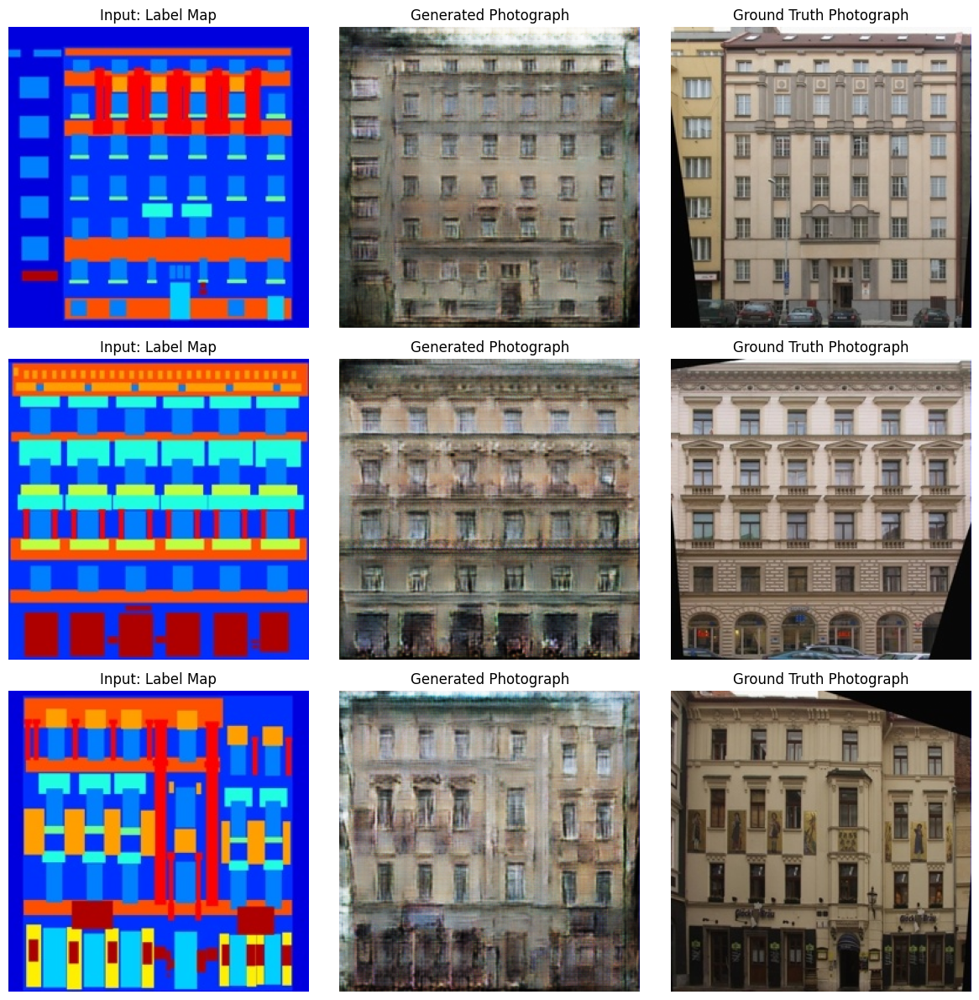

In [15]:
# Cell 10: Visualize Pix2Pix Results

import torch
import matplotlib.pyplot as plt

generator.eval()

# Select three test examples
num_examples = 3
shown = 0

fig, axes = plt.subplots(num_examples, 3, figsize=(12, 4 * num_examples))

with torch.no_grad():
    for input_image, target_image in test_loader:

        input_image = input_image.to(DEVICE)
        target_image = target_image.to(DEVICE)

        # Generate a photograph
        generated_image = generator(input_image)

        # Convert tensors from [-1, 1] to [0, 1]
        input_display = (
            input_image[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        ).clamp(0, 1)

        generated_display = (
            generated_image[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        ).clamp(0, 1)

        target_display = (
            target_image[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        ).clamp(0, 1)

        axes[shown, 0].imshow(input_display)
        axes[shown, 0].set_title("Input: Label Map")
        axes[shown, 0].axis("off")

        axes[shown, 1].imshow(generated_display)
        axes[shown, 1].set_title("Generated Photograph")
        axes[shown, 1].axis("off")

        axes[shown, 2].imshow(target_display)
        axes[shown, 2].set_title("Ground Truth Photograph")
        axes[shown, 2].axis("off")

        shown += 1

        if shown >= num_examples:
            break

plt.tight_layout()
plt.show()

In [16]:
# Cell 11: Evaluate Pix2Pix using MAE and PSNR

import torch
import math

generator.eval()

total_mae = 0.0
total_psnr = 0.0
num_images = 0

with torch.no_grad():
    for input_image, target_image in test_loader:

        input_image = input_image.to(DEVICE)
        target_image = target_image.to(DEVICE)

        # Generate the photograph
        generated_image = generator(input_image)

        # Convert normalized tensors [-1, 1] to [0, 1]
        generated_image = (generated_image * 0.5 + 0.5).clamp(0, 1)
        target_image = (target_image * 0.5 + 0.5).clamp(0, 1)

        # Calculate MAE
        mae = torch.mean(torch.abs(generated_image - target_image)).item()

        # Calculate PSNR
        mse = torch.mean((generated_image - target_image) ** 2).item()

        if mse == 0:
            psnr = float("inf")
        else:
            psnr = 10 * math.log10(1.0 / mse)

        total_mae += mae
        total_psnr += psnr
        num_images += 1

# Average metrics across all test images
average_mae = total_mae / num_images
average_psnr = total_psnr / num_images

print(f"Number of test images: {num_images}")
print(f"Average MAE: {average_mae:.4f}")
print(f"Average PSNR: {average_psnr:.2f} dB")

Number of test images: 106
Average MAE: 0.1847
Average PSNR: 12.57 dB


In [17]:
# Cell 12: Plot Pix2Pix Training Losses

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(G_losses) + 1), G_losses, label="Generator Total Loss")
plt.plot(range(1, len(D_losses) + 1), D_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pix2Pix Training Loss Curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot the generator's individual loss components
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(G_GAN_losses) + 1), G_GAN_losses, label="Adversarial Loss")
plt.plot(range(1, len(G_L1_losses) + 1), G_L1_losses, label="L1 Reconstruction Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator Loss Components")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

NameError: name 'G_losses' is not defined

<Figure size 1000x500 with 0 Axes>

In [19]:
# Cell 12.1: Check available training variables

print("Available loss-related variables:")

for name, value in globals().copy().items():
    if "loss" in name.lower() and not name.startswith("_"):
        if isinstance(value, (list, tuple)):
            print(f"{name}: list with {len(value)} values")
        elif isinstance(value, (int, float)):
            print(f"{name}: {value}")

Available loss-related variables:


In [20]:
# Cell 12.2: Inspect variables from the training process

print("Training-related variables:")

for name, value in globals().copy().items():
    if any(word in name.lower() for word in
           ["epoch", "train", "history", "generator", "discriminator"]):
        if not name.startswith("_"):
            if isinstance(value, (list, tuple)):
                print(f"{name}: list, length = {len(value)}")
            elif isinstance(value, dict):
                print(f"{name}: dictionary, keys = {list(value.keys())[:10]}")
            elif isinstance(value, (int, float, str)):
                print(f"{name}: {value}")
            elif hasattr(value, "shape"):
                print(f"{name}: shape = {value.shape}")

Training-related variables:
TRAIN_DIR: /content/pix2pix_data/facades/train
train_images: list, length = 400
NUM_EPOCHS: 50
history: dictionary, keys = ['G_total', 'G_GAN', 'G_L1', 'D_total']
epoch: 49
epoch_G_total: 7943.533157348633
epoch_G_GAN: 907.6721034049988
epoch_G_L1: 70.35861073434353
epoch_D_total: 135.88555874675512


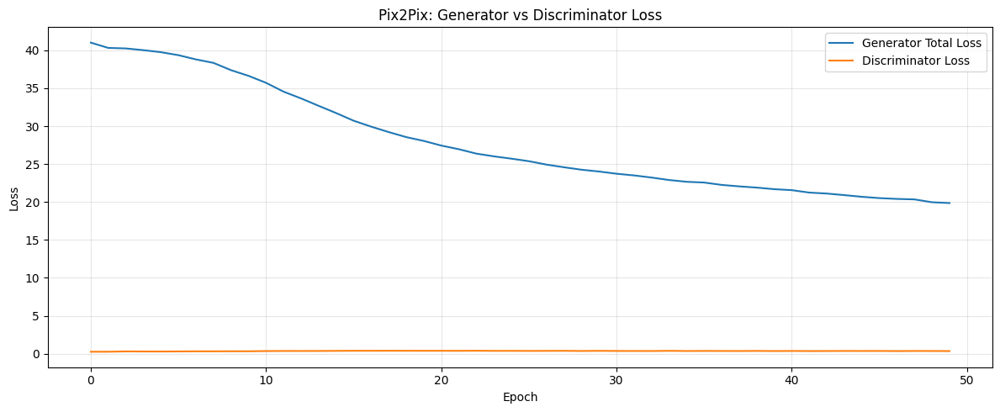

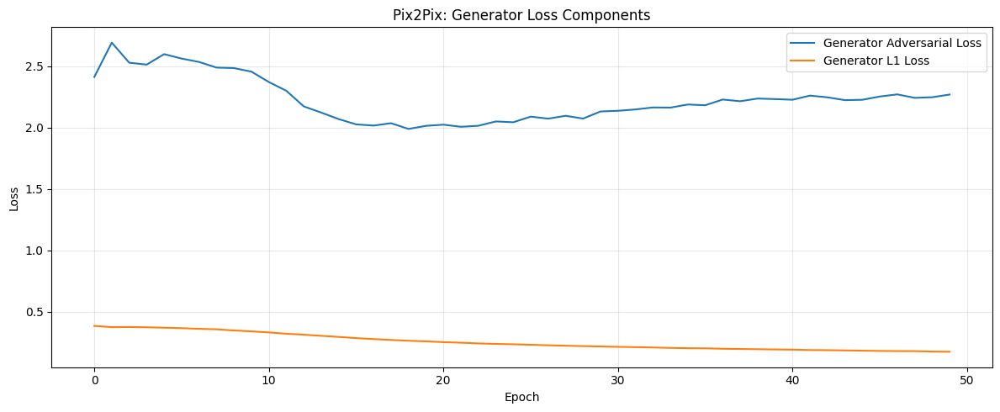

Final Training Losses
-----------------------------------
G_total: 19.8588
G_GAN: 2.2692
G_L1: 0.1759
D_total: 0.3397
-----------------------------------


In [21]:
# Cell 12.3: Plot Pix2Pix Training History

import matplotlib.pyplot as plt

# Plot generator and discriminator losses
plt.figure(figsize=(12, 5))

plt.plot(history["G_total"], label="Generator Total Loss")
plt.plot(history["D_total"], label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pix2Pix: Generator vs Discriminator Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Plot individual generator loss components
plt.figure(figsize=(12, 5))

plt.plot(history["G_GAN"], label="Generator Adversarial Loss")
plt.plot(history["G_L1"], label="Generator L1 Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pix2Pix: Generator Loss Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Print final loss values
print("Final Training Losses")
print("-" * 35)

for name, values in history.items():
    print(f"{name}: {values[-1]:.4f}")

print("-" * 35)

In [22]:
# Cell 13: Save trained Pix2Pix models

import os
import torch

# Create directory for checkpoints
CHECKPOINT_DIR = "/content/pix2pix_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Save generator
torch.save(
    generator.state_dict(),
    os.path.join(CHECKPOINT_DIR, "pix2pix_generator.pth")
)

# Save discriminator
torch.save(
    discriminator.state_dict(),
    os.path.join(CHECKPOINT_DIR, "pix2pix_discriminator.pth")
)

# Save training history
torch.save(
    history,
    os.path.join(CHECKPOINT_DIR, "training_history.pth")
)

print("Models and training history saved successfully!")
print("Saved files:")

for filename in os.listdir(CHECKPOINT_DIR):
    filepath = os.path.join(CHECKPOINT_DIR, filename)
    print(f"{filename}: {os.path.getsize(filepath) / (1024**2):.2f} MB")

Models and training history saved successfully!
Saved files:
pix2pix_discriminator.pth: 2.67 MB
training_history.pth: 0.00 MB
pix2pix_generator.pth: 51.96 MB


In [23]:
# Cell 14: Verify saved Pix2Pix checkpoints

import os
import torch

CHECKPOINT_DIR = "/content/pix2pix_checkpoints"

required_files = [
    "pix2pix_generator.pth",
    "pix2pix_discriminator.pth",
    "training_history.pth"
]

for filename in required_files:
    filepath = os.path.join(CHECKPOINT_DIR, filename)

    if os.path.exists(filepath):
        print(f"OK: {filename}")
    else:
        print(f"MISSING: {filename}")

# Verify that the generator checkpoint can be loaded
generator_state = torch.load(
    os.path.join(CHECKPOINT_DIR, "pix2pix_generator.pth"),
    map_location=DEVICE,
    weights_only=True
)

print("\nGenerator checkpoint loaded successfully.")
print(f"Number of parameter tensors: {len(generator_state)}")

OK: pix2pix_generator.pth
OK: pix2pix_discriminator.pth
OK: training_history.pth

Generator checkpoint loaded successfully.
Number of parameter tensors: 84


In [24]:
# Cell 15: Initialize the L1-loss ablation experiment

import torch
import torch.nn as nn
import torch.optim as optim
import os

# Separate directory for the ablation model
ABLATION_DIR = "/content/pix2pix_ablation"
os.makedirs(ABLATION_DIR, exist_ok=True)

# Create fresh models using the same architecture
ablation_generator = UNetGenerator(
    in_channels=3,
    out_channels=3,
    base_channels=32
).to(DEVICE)

ablation_discriminator = PatchGANDiscriminator(
    in_channels=3,
    base_channels=32
).to(DEVICE)

# Use the same adversarial loss as the original experiment
ablation_criterion_GAN = nn.BCEWithLogitsLoss()

# Optimizers with the same hyperparameters
ablation_optimizer_G = optim.Adam(
    ablation_generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

ablation_optimizer_D = optim.Adam(
    ablation_discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("Ablation models initialized successfully.")
print(f"Device: {DEVICE}")
print(f"Generator parameters: {sum(p.numel() for p in ablation_generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in ablation_discriminator.parameters()):,}")
print("Ablation objective: adversarial loss only (no L1 loss)")
print("Original checkpoints remain unchanged.")

Ablation models initialized successfully.
Device: cuda
Generator parameters: 13,608,547
Discriminator parameters: 694,689
Ablation objective: adversarial loss only (no L1 loss)
Original checkpoints remain unchanged.


In [25]:
# Cell 16: Train Pix2Pix Ablation Without L1 Loss

import time
import torch

ABLATION_EPOCHS = 50

ablation_history = {
    "G_GAN": [],
    "D_total": []
}

for epoch in range(ABLATION_EPOCHS):
    ablation_generator.train()
    ablation_discriminator.train()

    epoch_G_GAN = 0.0
    epoch_D_total = 0.0
    num_batches = 0

    start_time = time.time()

    for input_image, real_image in train_loader:
        input_image = input_image.to(DEVICE)
        real_image = real_image.to(DEVICE)

        # -------------------------
        # 1. Train Discriminator
        # -------------------------
        ablation_optimizer_D.zero_grad(set_to_none=True)

        with torch.no_grad():
            fake_image = ablation_generator(input_image)

        # Real image pairs
        real_logits = ablation_discriminator(
            input_image, real_image
        )
        real_labels = torch.ones_like(real_logits)
        loss_D_real = ablation_criterion_GAN(
            real_logits, real_labels
        )

        # Generated image pairs
        fake_logits = ablation_discriminator(
            input_image, fake_image
        )
        fake_labels = torch.zeros_like(fake_logits)
        loss_D_fake = ablation_criterion_GAN(
            fake_logits, fake_labels
        )

        loss_D = 0.5 * (loss_D_real + loss_D_fake)
        loss_D.backward()
        ablation_optimizer_D.step()

        # -------------------------
        # 2. Train Generator
        # -------------------------
        ablation_optimizer_G.zero_grad(set_to_none=True)

        generated_image = ablation_generator(input_image)

        generated_logits = ablation_discriminator(
            input_image, generated_image
        )

        # Generator tries to fool the discriminator
        target_labels = torch.ones_like(generated_logits)

        loss_G_GAN = ablation_criterion_GAN(
            generated_logits, target_labels
        )

        # No L1 reconstruction loss in this experiment
        loss_G_GAN.backward()
        ablation_optimizer_G.step()

        epoch_G_GAN += loss_G_GAN.item()
        epoch_D_total += loss_D.item()
        num_batches += 1

    # Average losses for this epoch
    avg_G_GAN = epoch_G_GAN / num_batches
    avg_D_total = epoch_D_total / num_batches

    ablation_history["G_GAN"].append(avg_G_GAN)
    ablation_history["D_total"].append(avg_D_total)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1:02d}/{ABLATION_EPOCHS}] "
        f"| D Loss: {avg_D_total:.4f} "
        f"| G GAN Loss: {avg_G_GAN:.4f} "
        f"| Time: {elapsed:.1f}s"
    )

print("\nAblation training completed!")

RuntimeError: Given groups=1, weight of size [32, 3, 4, 4], expected input[1, 6, 256, 256] to have 3 channels, but got 6 channels instead

In [26]:
# Cell 16.1: Inspect discriminator input channels

print("Discriminator architecture:")
print(ablation_discriminator)

print("\nFirst convolution:")
print(ablation_discriminator.model[0])

Discriminator architecture:
PatchGANDiscriminator(
  (model): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): LeakyReLU(negative_slope=0.2, inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
    )
    (3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.

In [27]:
# Cell 16.2: Reinitialize the ablation discriminator correctly

# The discriminator must accept 6 channels:
# 3 channels for the input label map
# 3 channels for the real/generated photograph

ablation_discriminator = PatchGANDiscriminator(
    in_channels=6,
    base_channels=32
).to(DEVICE)

# Reinitialize the discriminator optimizer because the model changed
ablation_optimizer_D = torch.optim.Adam(
    ablation_discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

# Verify the first convolution
print("First convolution:")
print(ablation_discriminator.model[0][0])

# Test the conditional input
with torch.no_grad():
    sample_input, sample_target = next(iter(train_loader))

    sample_input = sample_input.to(DEVICE)
    sample_target = sample_target.to(DEVICE)

    sample_output = ablation_discriminator(
        sample_input,
        sample_target
    )

print("\nDiscriminator test passed!")
print("Input shape:", sample_input.shape)
print("Target shape:", sample_target.shape)
print("Output shape:", sample_output.shape)

First convolution:
Conv2d(6, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))

Discriminator test passed!
Input shape: torch.Size([1, 3, 256, 256])
Target shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 30, 30])


In [28]:
# Cell 16.3: Train Pix2Pix without L1 reconstruction loss

import time
import torch

ABLATION_EPOCHS = 50

ablation_history = {
    "G_GAN": [],
    "D_total": []
}

for epoch in range(ABLATION_EPOCHS):
    ablation_generator.train()
    ablation_discriminator.train()

    epoch_G_GAN = 0.0
    epoch_D_total = 0.0
    num_batches = 0

    start_time = time.time()

    for input_image, real_image in train_loader:
        input_image = input_image.to(DEVICE)
        real_image = real_image.to(DEVICE)

        # -------------------------
        # 1. Train discriminator
        # -------------------------
        ablation_optimizer_D.zero_grad(set_to_none=True)

        with torch.no_grad():
            fake_image = ablation_generator(input_image)

        real_logits = ablation_discriminator(input_image, real_image)
        fake_logits = ablation_discriminator(input_image, fake_image)

        loss_D_real = ablation_criterion_GAN(
            real_logits, torch.ones_like(real_logits)
        )

        loss_D_fake = ablation_criterion_GAN(
            fake_logits, torch.zeros_like(fake_logits)
        )

        loss_D = 0.5 * (loss_D_real + loss_D_fake)

        loss_D.backward()
        ablation_optimizer_D.step()

        # -------------------------
        # 2. Train generator
        # -------------------------
        ablation_optimizer_G.zero_grad(set_to_none=True)

        generated_image = ablation_generator(input_image)
        generated_logits = ablation_discriminator(
            input_image, generated_image
        )

        loss_G_GAN = ablation_criterion_GAN(
            generated_logits,
            torch.ones_like(generated_logits)
        )

        # No L1 reconstruction loss
        loss_G_GAN.backward()
        ablation_optimizer_G.step()

        epoch_G_GAN += loss_G_GAN.item()
        epoch_D_total += loss_D.item()
        num_batches += 1

    avg_G_GAN = epoch_G_GAN / num_batches
    avg_D_total = epoch_D_total / num_batches

    ablation_history["G_GAN"].append(avg_G_GAN)
    ablation_history["D_total"].append(avg_D_total)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1:02d}/{ABLATION_EPOCHS}] "
        f"| D Loss: {avg_D_total:.4f} "
        f"| G GAN Loss: {avg_G_GAN:.4f} "
        f"| Time: {elapsed:.1f}s"
    )

print("\nAblation training completed!")

Epoch [01/50] | D Loss: 0.6776 | G GAN Loss: 0.8287 | Time: 10.8s
Epoch [02/50] | D Loss: 0.6308 | G GAN Loss: 1.1228 | Time: 10.9s
Epoch [03/50] | D Loss: 0.6134 | G GAN Loss: 1.1888 | Time: 10.9s
Epoch [04/50] | D Loss: 0.6113 | G GAN Loss: 1.2252 | Time: 10.9s
Epoch [05/50] | D Loss: 0.5919 | G GAN Loss: 1.2646 | Time: 11.0s
Epoch [06/50] | D Loss: 0.5805 | G GAN Loss: 1.3168 | Time: 11.1s
Epoch [07/50] | D Loss: 0.5707 | G GAN Loss: 1.3550 | Time: 11.2s
Epoch [08/50] | D Loss: 0.5576 | G GAN Loss: 1.4312 | Time: 11.1s
Epoch [09/50] | D Loss: 0.5439 | G GAN Loss: 1.4682 | Time: 11.0s
Epoch [10/50] | D Loss: 0.5370 | G GAN Loss: 1.5221 | Time: 11.0s
Epoch [11/50] | D Loss: 0.4884 | G GAN Loss: 1.6423 | Time: 11.0s
Epoch [12/50] | D Loss: 0.4850 | G GAN Loss: 1.8025 | Time: 11.0s
Epoch [13/50] | D Loss: 0.4624 | G GAN Loss: 1.8053 | Time: 11.1s
Epoch [14/50] | D Loss: 0.4611 | G GAN Loss: 1.8363 | Time: 11.1s
Epoch [15/50] | D Loss: 0.4614 | G GAN Loss: 1.8747 | Time: 11.0s
Epoch [16/

In [29]:
# Cell 17: Save ablation model checkpoints

import os
import torch

ABLATION_DIR = "/content/pix2pix_ablation"
os.makedirs(ABLATION_DIR, exist_ok=True)

torch.save(
    ablation_generator.state_dict(),
    os.path.join(ABLATION_DIR, "ablation_generator.pth")
)

torch.save(
    ablation_discriminator.state_dict(),
    os.path.join(ABLATION_DIR, "ablation_discriminator.pth")
)

torch.save(
    ablation_history,
    os.path.join(ABLATION_DIR, "ablation_history.pth")
)

print("Ablation checkpoints saved successfully!")

for filename in os.listdir(ABLATION_DIR):
    filepath = os.path.join(ABLATION_DIR, filename)
    print(f"{filename}: {os.path.getsize(filepath) / (1024**2):.2f} MB")

Ablation checkpoints saved successfully!
ablation_history.pth: 0.00 MB
ablation_discriminator.pth: 2.67 MB
ablation_generator.pth: 51.96 MB


In [30]:
# Cell 18: Compare original Pix2Pix and ablation models

import torch
import math

def evaluate_model(model, dataloader, device):
    model.eval()

    total_mae = 0.0
    total_psnr = 0.0
    num_images = 0

    with torch.no_grad():
        for input_image, target_image in dataloader:
            input_image = input_image.to(device)
            target_image = target_image.to(device)

            generated_image = model(input_image)

            # Convert from [-1, 1] to [0, 1]
            generated_image = (
                generated_image * 0.5 + 0.5
            ).clamp(0, 1)

            target_image = (
                target_image * 0.5 + 0.5
            ).clamp(0, 1)

            mae = torch.mean(
                torch.abs(generated_image - target_image)
            ).item()

            mse = torch.mean(
                (generated_image - target_image) ** 2
            ).item()

            psnr = (
                float("inf")
                if mse == 0
                else 10 * math.log10(1.0 / mse)
            )

            total_mae += mae
            total_psnr += psnr
            num_images += 1

    return total_mae / num_images, total_psnr / num_images


# Evaluate the original model
original_mae, original_psnr = evaluate_model(
    generator, test_loader, DEVICE
)

# Evaluate the ablation model
ablation_mae, ablation_psnr = evaluate_model(
    ablation_generator, test_loader, DEVICE
)

print("\n========== TEST RESULTS ==========")
print(f"Test images: {len(test_loader.dataset)}")

print("\nOriginal Pix2Pix (GAN + L1):")
print(f"MAE:  {original_mae:.4f}")
print(f"PSNR: {original_psnr:.2f} dB")

print("\nAblation (GAN only):")
print(f"MAE:  {ablation_mae:.4f}")
print(f"PSNR: {ablation_psnr:.2f} dB")

print("\n========== COMPARISON ==========")

if original_mae < ablation_mae:
    print("Original Pix2Pix has lower MAE.")
elif original_mae > ablation_mae:
    print("Ablation model has lower MAE.")
else:
    print("Both models have equal MAE.")

if original_psnr > ablation_psnr:
    print("Original Pix2Pix has higher PSNR.")
elif original_psnr < ablation_psnr:
    print("Ablation model has higher PSNR.")
else:
    print("Both models have equal PSNR.")


========== TEST RESULTS ==========
Test images: 106

Original Pix2Pix (GAN + L1):
MAE:  0.1847
PSNR: 12.57 dB

Ablation (GAN only):
MAE:  0.2446
PSNR: 10.29 dB

========== COMPARISON ==========
Original Pix2Pix has lower MAE.
Original Pix2Pix has higher PSNR.


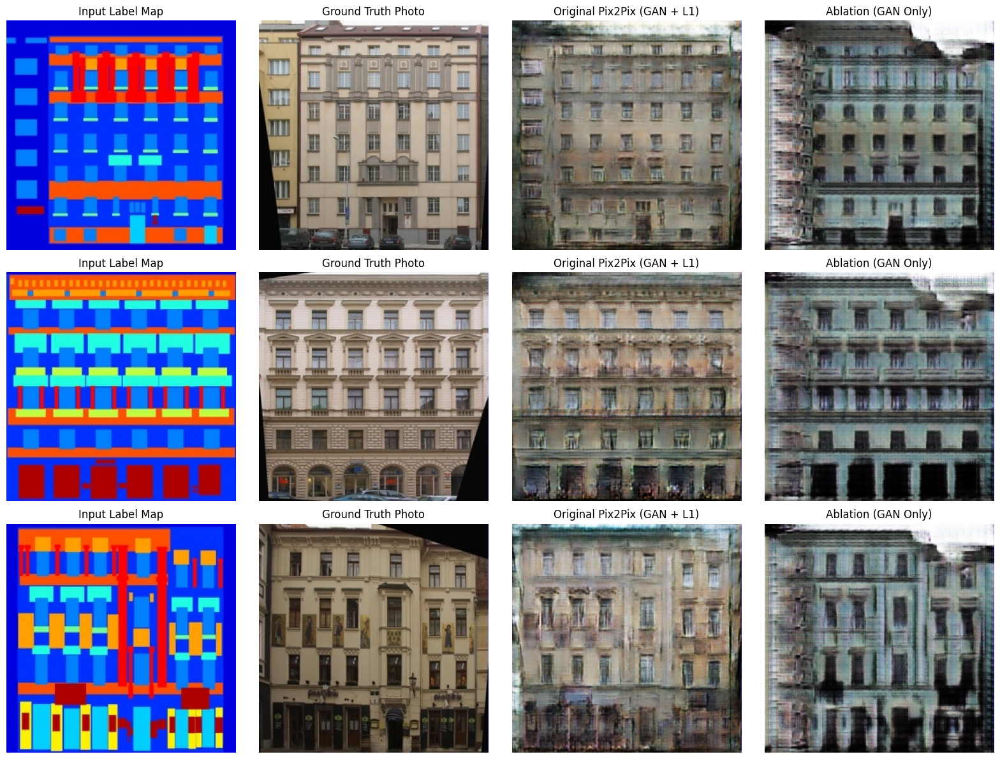

In [31]:
# Cell 19: Visual comparison of original and ablation models

import torch
import matplotlib.pyplot as plt

generator.eval()
ablation_generator.eval()

num_examples = 3
shown = 0

fig, axes = plt.subplots(
    num_examples, 4,
    figsize=(16, 4 * num_examples)
)

with torch.no_grad():
    for input_image, target_image in test_loader:

        input_image = input_image.to(DEVICE)
        target_image = target_image.to(DEVICE)

        # Original Pix2Pix prediction
        original_generated = generator(input_image)

        # Ablation prediction: no L1 loss
        ablation_generated = ablation_generator(input_image)

        # Convert images from [-1, 1] to [0, 1]
        input_display = (
            input_image[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        ).clamp(0, 1)

        target_display = (
            target_image[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        ).clamp(0, 1)

        original_display = (
            original_generated[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        ).clamp(0, 1)

        ablation_display = (
            ablation_generated[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        ).clamp(0, 1)

        axes[shown, 0].imshow(input_display)
        axes[shown, 0].set_title("Input Label Map")

        axes[shown, 1].imshow(target_display)
        axes[shown, 1].set_title("Ground Truth Photo")

        axes[shown, 2].imshow(original_display)
        axes[shown, 2].set_title("Original Pix2Pix (GAN + L1)")

        axes[shown, 3].imshow(ablation_display)
        axes[shown, 3].set_title("Ablation (GAN Only)")

        for col in range(4):
            axes[shown, col].axis("off")

        shown += 1

        if shown >= num_examples:
            break

plt.tight_layout()
plt.show()

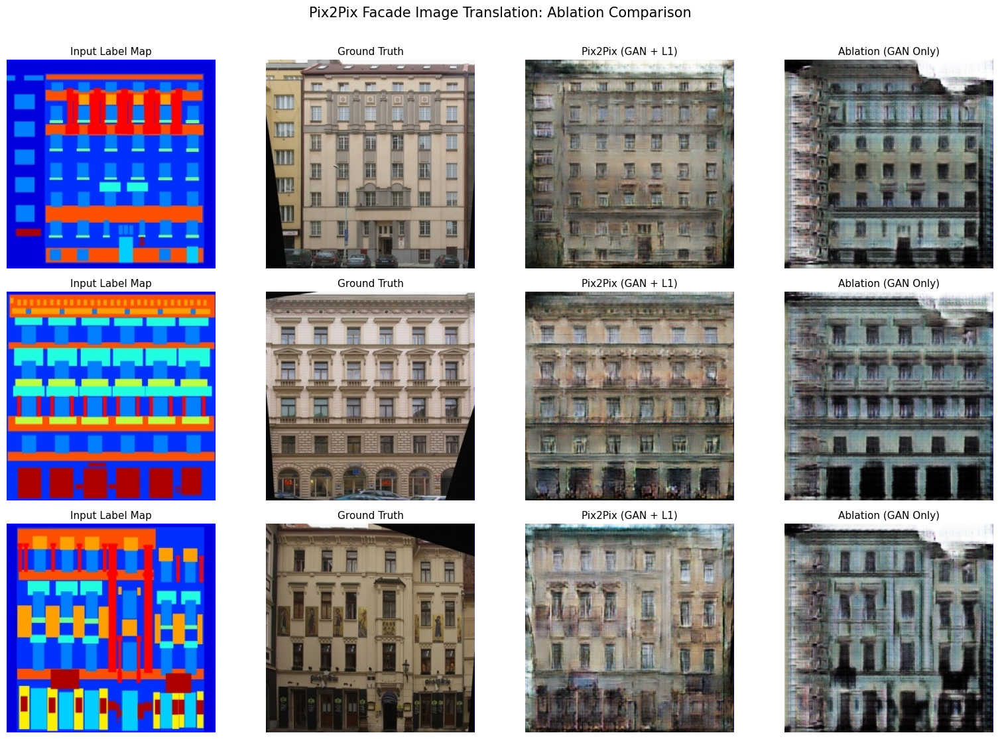


Comparison figures saved successfully:
/content/pix2pix_results/pix2pix_ablation_comparison.png
/content/pix2pix_results/pix2pix_ablation_comparison.pdf


In [32]:
# Cell 20: Save publication-quality comparison figure

import os
import torch
import matplotlib.pyplot as plt

# Create output directory
RESULTS_DIR = "/content/pix2pix_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Set both models to evaluation mode
generator.eval()
ablation_generator.eval()

num_examples = 3
shown = 0

fig, axes = plt.subplots(
    num_examples,
    4,
    figsize=(16, 11)
)

with torch.no_grad():
    for input_image, target_image in test_loader:

        input_image = input_image.to(DEVICE)
        target_image = target_image.to(DEVICE)

        # Generate outputs using both models
        original_generated = generator(input_image)
        ablation_generated = ablation_generator(input_image)

        # Convert normalized tensors [-1, 1] to display range [0, 1]
        images = [
            input_image[0],
            target_image[0],
            original_generated[0],
            ablation_generated[0]
        ]

        titles = [
            "Input Label Map",
            "Ground Truth",
            "Pix2Pix (GAN + L1)",
            "Ablation (GAN Only)"
        ]

        for col, (image_tensor, title) in enumerate(
            zip(images, titles)
        ):
            image_display = (
                image_tensor.detach()
                .cpu()
                .permute(1, 2, 0)
                .mul(0.5)
                .add(0.5)
                .clamp(0, 1)
            )

            axes[shown, col].imshow(image_display)
            axes[shown, col].set_title(title, fontsize=11)
            axes[shown, col].axis("off")

        shown += 1

        if shown >= num_examples:
            break

fig.suptitle(
    "Pix2Pix Facade Image Translation: Ablation Comparison",
    fontsize=15,
    y=1.01
)

plt.tight_layout()

# Save high-resolution PNG
png_path = os.path.join(
    RESULTS_DIR,
    "pix2pix_ablation_comparison.png"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

# Save PDF for the report
pdf_path = os.path.join(
    RESULTS_DIR,
    "pix2pix_ablation_comparison.pdf"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nComparison figures saved successfully:")
print(png_path)
print(pdf_path)

In [33]:
# Cell 21: Save quantitative evaluation results

import os
import pandas as pd

RESULTS_DIR = "/content/pix2pix_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

results_df = pd.DataFrame({
    "Model": [
        "Pix2Pix (GAN + L1)",
        "Ablation (GAN Only)"
    ],
    "Test Images": [106, 106],
    "Epochs": [50, 50],
    "MAE": [original_mae, ablation_mae],
    "PSNR_dB": [original_psnr, ablation_psnr],
    "L1_Loss_Used": ["Yes", "No"]
})

csv_path = os.path.join(
    RESULTS_DIR,
    "pix2pix_evaluation_results.csv"
)

results_df.to_csv(csv_path, index=False)

print(results_df.to_string(index=False))
print(f"\nResults saved to: {csv_path}")

              Model  Test Images  Epochs      MAE   PSNR_dB L1_Loss_Used
 Pix2Pix (GAN + L1)          106      50 0.184699 12.565808          Yes
Ablation (GAN Only)          106      50 0.244560 10.287461           No

Results saved to: /content/pix2pix_results/pix2pix_evaluation_results.csv


In [34]:
# Cell 22: Verify project artifacts

import os

paths_to_check = [
    "/content/pix2pix_checkpoints/pix2pix_generator.pth",
    "/content/pix2pix_checkpoints/pix2pix_discriminator.pth",
    "/content/pix2pix_checkpoints/training_history.pth",
    "/content/pix2pix_ablation/ablation_generator.pth",
    "/content/pix2pix_ablation/ablation_discriminator.pth",
    "/content/pix2pix_ablation/ablation_history.pth",
    "/content/pix2pix_results/pix2pix_ablation_comparison.png",
    "/content/pix2pix_results/pix2pix_ablation_comparison.pdf",
    "/content/pix2pix_results/pix2pix_evaluation_results.csv"
]

print("PROJECT ARTIFACT VERIFICATION")
print("=" * 65)

all_found = True

for path in paths_to_check:
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"[OK] {os.path.basename(path)} — {size_mb:.2f} MB")
    else:
        print(f"[MISSING] {path}")
        all_found = False

print("=" * 65)

if all_found:
    print("All expected project artifacts are present.")
else:
    print("Some artifacts are missing. Check the corresponding cells.")

PROJECT ARTIFACT VERIFICATION
[OK] pix2pix_generator.pth — 51.96 MB
[OK] pix2pix_discriminator.pth — 2.67 MB
[OK] training_history.pth — 0.00 MB
[OK] ablation_generator.pth — 51.96 MB
[OK] ablation_discriminator.pth — 2.67 MB
[OK] ablation_history.pth — 0.00 MB
[OK] pix2pix_ablation_comparison.png — 2.40 MB
[OK] pix2pix_ablation_comparison.pdf — 1.70 MB
[OK] pix2pix_evaluation_results.csv — 0.00 MB
All expected project artifacts are present.


# Pix2Pix: Image-to-Image Translation on Facades

## Overview

This project implements Pix2Pix, a conditional GAN-based
image-to-image translation model, using PyTorch.

The task is to translate architectural label maps into
photorealistic building facade images.

The project includes a U-Net generator, a conditional
PatchGAN discriminator, model training, test evaluation,
and an ablation study investigating the effect of removing
the L1 reconstruction loss.

## Dataset

Dataset: Facades

Training images: 400
Validation images: 100
Test images: 106

Images are resized to 256 × 256 pixels and normalized
to the range [-1, 1].

The input is the architectural label map, and the target
is the corresponding real photograph.

## Model Architecture

### Generator
- U-Net encoder-decoder
- Skip connections
- Transposed convolution layers
- Tanh output activation

### Discriminator
- Conditional PatchGAN
- Concatenated input label map and target/generated image
- Patch-level real/fake predictions

## Training Configuration

- Framework: PyTorch
- Input resolution: 256 × 256
- Batch size: 1
- Training epochs: 50
- Optimizer: Adam
- Learning rate: 0.0002
- Adam betas: (0.5, 0.999)
- L1 loss weight: 100

## Evaluation

The original Pix2Pix model was evaluated on 106 test images.

| Model | MAE | PSNR |
|---|---:|---:|
| Pix2Pix (GAN + L1) | 0.184699 | 12.5658 dB |
| GAN-only ablation | 0.244560 | 10.2875 dB |

Lower MAE is better. Higher PSNR is better.

## Ablation Study

The original model uses:

L_G = L_GAN + 100 × L_L1

The ablation model uses:

L_G = L_GAN

Under the current experimental setup, the original model
achieved lower MAE and higher PSNR than the ablation model.

This suggests that L1 reconstruction loss improves
pixel-level reconstruction accuracy in this experiment.

## Limitations

- Generated images contain visible reconstruction artifacts.
- Results are based on one training run per configuration.
- Results may vary with random initialization and training settings.
- MAE and PSNR do not fully measure perceptual realism.

## Project Artifacts

The results directory contains:
- Visual comparison figure in PNG format
- Comparison figure in PDF format
- Quantitative evaluation results in CSV format

Model checkpoints can be provided separately.

## Future Work

- Investigate longer training schedules.
- Improve training stability.
- Evaluate additional image-quality metrics.
- Repeat experiments using multiple random seeds.
- Compare generated images using perceptual evaluation.

In [35]:
import os

print("Current directory:", os.getcwd())

print("\nCheckpoint files:")
for f in [
    "pix2pix_generator.pth",
    "pix2pix_discriminator.pth",
    "ablation_generator.pth",
    "ablation_discriminator.pth",
]:
    if os.path.exists(f):
        print(f"✅ {f} — {os.path.getsize(f) / (1024**2):.2f} MB")
    else:
        print(f"❌ {f} — not found")

print("\nResults directory:")
results_dir = "/content/pix2pix_results"

if os.path.exists(results_dir):
    for f in os.listdir(results_dir):
        print(f"✅ {f}")
else:
    print("Results directory not found.")

Current directory: /content

Checkpoint files:
❌ pix2pix_generator.pth — not found
❌ pix2pix_discriminator.pth — not found
❌ ablation_generator.pth — not found
❌ ablation_discriminator.pth — not found

Results directory:
✅ pix2pix_evaluation_results.csv
✅ pix2pix_ablation_comparison.png
✅ pix2pix_ablation_comparison.pdf


In [36]:
import os

search_dirs = [
    "/content",
    "/content/drive/MyDrive",
]

checkpoint_names = {
    "pix2pix_generator.pth",
    "pix2pix_discriminator.pth",
    "ablation_generator.pth",
    "ablation_discriminator.pth",
}

found_files = []

for base_dir in search_dirs:
    if not os.path.exists(base_dir):
        continue

    print(f"\nSearching in: {base_dir}")

    for root, dirs, files in os.walk(base_dir):
        # Avoid searching large cache folders
        dirs[:] = [
            d for d in dirs
            if d not in {"node_modules", ".cache", "__pycache__"}
        ]

        for filename in files:
            if filename in checkpoint_names:
                path = os.path.join(root, filename)
                found_files.append(path)
                print(
                    f"✅ {path} "
                    f"({os.path.getsize(path) / (1024**2):.2f} MB)"
                )

if not found_files:
    print("\n❌ No model checkpoints found in the searched directories.")


Searching in: /content
✅ /content/pix2pix_ablation/ablation_discriminator.pth (2.67 MB)
✅ /content/pix2pix_ablation/ablation_generator.pth (51.96 MB)
✅ /content/pix2pix_checkpoints/pix2pix_discriminator.pth (2.67 MB)
✅ /content/pix2pix_checkpoints/pix2pix_generator.pth (51.96 MB)


In [37]:
import os
import shutil

# Create project directory
PROJECT_DIR = "/content/pix2pix-facades"

folders = [
    "notebooks",
    "reports",
    "results",
    "checkpoints",
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

# Copy evaluation results and comparison figures
results_source = "/content/pix2pix_results"
results_destination = os.path.join(PROJECT_DIR, "results")

for filename in [
    "pix2pix_evaluation_results.csv",
    "pix2pix_ablation_comparison.png",
    "pix2pix_ablation_comparison.pdf",
]:
    source = os.path.join(results_source, filename)
    destination = os.path.join(results_destination, filename)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print(f"✅ Copied {filename}")
    else:
        print(f"⚠️ Not found: {source}")

# Copy trained model checkpoints into the project folder
checkpoint_sources = {
    "pix2pix_generator.pth":
        "/content/pix2pix_checkpoints/pix2pix_generator.pth",
    "pix2pix_discriminator.pth":
        "/content/pix2pix_checkpoints/pix2pix_discriminator.pth",
    "ablation_generator.pth":
        "/content/pix2pix_ablation/ablation_generator.pth",
    "ablation_discriminator.pth":
        "/content/pix2pix_ablation/ablation_discriminator.pth",
}

checkpoint_destination = os.path.join(PROJECT_DIR, "checkpoints")

for filename, source in checkpoint_sources.items():
    if os.path.exists(source):
        destination = os.path.join(checkpoint_destination, filename)
        shutil.copy2(source, destination)
        size_mb = os.path.getsize(destination) / (1024**2)
        print(f"✅ Copied {filename} ({size_mb:.2f} MB)")
    else:
        print(f"⚠️ Checkpoint not found: {source}")

print("\nProject structure prepared:")
for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in files:
        print(f"{indent}  {filename}")

print("\nProject directory:", PROJECT_DIR)

✅ Copied pix2pix_evaluation_results.csv
✅ Copied pix2pix_ablation_comparison.png
✅ Copied pix2pix_ablation_comparison.pdf
✅ Copied pix2pix_generator.pth (51.96 MB)
✅ Copied pix2pix_discriminator.pth (2.67 MB)
✅ Copied ablation_generator.pth (51.96 MB)
✅ Copied ablation_discriminator.pth (2.67 MB)

Project structure prepared:
pix2pix-facades/
  reports/
  checkpoints/
    pix2pix_discriminator.pth
    pix2pix_generator.pth
    ablation_discriminator.pth
    ablation_generator.pth
  notebooks/
  results/
    pix2pix_evaluation_results.csv
    pix2pix_ablation_comparison.png
    pix2pix_ablation_comparison.pdf

Project directory: /content/pix2pix-facades


In [40]:
import os

PROJECT_DIR = "/content/pix2pix-facades"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Create README.md
readme_content = """
# Pix2Pix: Image-to-Image Translation with Conditional GANs

## Overview
This project implements Pix2Pix in PyTorch to translate architectural facade label maps into realistic facade photographs using a conditional Generative Adversarial Network (cGAN).

## Architecture
- Generator: U-Net encoder-decoder with skip connections.
- Discriminator: Conditional PatchGAN.
- Adversarial loss: Encourages realistic generated images.
- L1 reconstruction loss: Encourages similarity to the paired target image.
- Generator objective: L_G = L_GAN + 100 * L1.

## Dataset
We use the Facades dataset.

- Training images: 400
- Validation images: 100
- Test images: 106
- Image resolution: 256 x 256
- Task: Facade label map -> facade photograph

Dataset download:
https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz

The dataset is not included in this repository.

## Experimental Results

| Model | MAE (lower is better) | PSNR in dB (higher is better) |
|---|---:|---:|
| Pix2Pix (GAN + L1) | 0.1847 | 12.5658 |
| GAN-only ablation | 0.2446 | 10.2875 |

The full model performed better on these test metrics than the GAN-only ablation. Results are specific to this implementation and training configuration.

See the results directory for the comparison figure and evaluation CSV.

## Repository Structure

```text
pix2pix-facades/
├── notebooks/
├── reports/
├── results/
├── checkpoints/
├── README.md
├── requirements.txt
└── .gitignore

_IncompleteInputError: incomplete input (1588628692.py, line 7)

In [41]:
from pathlib import Path

PROJECT_DIR = Path("/content/pix2pix-facades")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory ready:", PROJECT_DIR.exists())

Project directory ready: True


In [42]:
from pathlib import Path

PROJECT_DIR = Path("/content/pix2pix-facades")

readme_lines = [
    "# Pix2Pix: Image-to-Image Translation",
    "",
    "## Overview",
    "A PyTorch implementation of Pix2Pix for translating architectural facade label maps into realistic photographs.",
    "",
    "## Architecture",
    "- Generator: U-Net with skip connections.",
    "- Discriminator: Conditional PatchGAN.",
    "- Generator loss: adversarial loss + 100 * L1 reconstruction loss.",
    "",
    "## Dataset",
    "- Training images: 400",
    "- Validation images: 100",
    "- Test images: 106",
    "- Image resolution: 256 x 256",
    "- Task: Facade label map to facade photograph.",
    "",
    "Dataset: https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz",
    "",
    "The dataset is not included in this repository.",
    "",
    "## Results",
    "",
    "| Model | MAE | PSNR (dB) |",
    "|---|---:|---:|",
    "| Pix2Pix (GAN + L1) | 0.1847 | 12.5658 |",
    "| GAN-only ablation | 0.2446 | 10.2875 |",
    "",
    "The full model performed better on these test metrics in this experiment.",
    "Results depend on the implementation and training configuration.",
    "",
    "See the results directory for the comparison figure and evaluation CSV.",
    "",
    "## Installation",
    "Install dependencies using:",
    "",
    "pip install -r requirements.txt",
    "",
    "## Running the Project",
    "1. Clone this repository.",
    "2. Install the dependencies.",
    "3. Download and extract the Facades dataset.",
    "4. Open the notebook in the notebooks directory.",
    "5. Run the notebook cells in order.",
    "",
    "A GPU is recommended for training.",
    "",
    "## Ablation Study",
    "The full model uses adversarial and L1 reconstruction losses.",
    "The ablation removes the L1 reconstruction loss.",
    "Both models were trained for 50 epochs.",
    "",
    "## Limitations",
    "This is a reduced-scale educational reproduction, not an exact reproduction of every experiment in the original paper.",
    "",
    "## Reference",
    "Isola et al., Image-to-Image Translation with Conditional Adversarial Networks, CVPR 2017.",
    "Paper: https://arxiv.org/abs/1611.07004",
    "",
    "## License",
    "Add an appropriate license before redistributing this project."
]

(PROJECT_DIR / "README.md").write_text(
    "\n".join(readme_lines) + "\n",
    encoding="utf-8"
)

print("README.md created successfully!")
print("File size:", (PROJECT_DIR / "README.md").stat().st_size, "bytes")

README.md created successfully!
File size: 1812 bytes


In [43]:
from pathlib import Path

PROJECT_DIR = Path("/content/pix2pix-facades")

requirements_lines = [
    "torch",
    "torchvision",
    "numpy",
    "Pillow",
    "matplotlib",
    "pandas",
    "scikit-image",
]

(PROJECT_DIR / "requirements.txt").write_text(
    "\n".join(requirements_lines) + "\n",
    encoding="utf-8"
)

gitignore_lines = [
    "__pycache__/",
    "*.py[cod]",
    ".ipynb_checkpoints/",
    "venv/",
    ".venv/",
    ".env",
    "*.log",
    "facades/",
    "facades.tar.gz",
    "checkpoints/*.pth",
]

(PROJECT_DIR / ".gitignore").write_text(
    "\n".join(gitignore_lines) + "\n",
    encoding="utf-8"
)

for filename in ["README.md", "requirements.txt", ".gitignore"]:
    path = PROJECT_DIR / filename
    print(("✅" if path.exists() else "❌"), filename)

✅ README.md
✅ requirements.txt
✅ .gitignore
